# Biweekly Report 3

## Candido Seneriches IV

# Comparative Analysis of AutoAugment, RandAugment, and Mixup

## Introduction
Data augmentation is a widely used technique in deep learning that improves model generalization by introducing variations into training data. Among data augmentation lies three distinct strategies: AutoAugment applies learned transformation policies, RandAugment simplifies augmentation through randomized operations, and Mixup generates new training examples by interpolating images and their labels. So naturally, one might ask, how well do these three methods compare against each other? 

In this experiment, these three methods will be tested against a standard augmentation baseline using a convolutional neural network (CNN) that's trained on the **CIFAR-10 dataset**. Under a controlled training setup, we investigate how each method affects classification accuracy, validation, and computational efficiency.Our goal is to compare these methods at a smaller scale than the original studies.

## Mathematical Motivation

Before moving further, let's define what these methods are. While all three methods aim to improve how well a neural network generalizes to unseen data, they approach this problem differently, and each comes with its own advantages and limitations.

To begin, suppose we have a training dataset $\mathcal{D}=\{(x_i,y_i)\}_{i=1}^{n}$, where $x_i$ represents an input image and $y_i$ is its corresponding class label. Normally, a neural network $f\theta$ is trained by minimizing the empirical risk

$$
\hat{R}(\theta)=\frac{1}{n}\sum_{i=1}^{n}\mathcal{L}(f_\theta(x_i),y_i),
$$

where $\theta$ represents the trainable parameters and $\mathcal{L}$ is the loss function. However, minimizing this loss does not necessarily mean that the model will perform equally well on images it has never encountered. This is where data augmentation comes in, as it introduces additional variations into the training process to help reduce overfitting.

### 1. AutoAugment

The first method being investigated is AutoAugment, which attempts to find effective combinations of image transformations through an automated policy-search process. These transformations can include rotations, translations, and adjustments to image properties such as brightness or contrast.

Mathematically, given an augmentation policy $\mathcal{P}$, we can express the training objective as

$$
\hat{R}_{\mathcal{P}}(\theta)
=
\frac{1}{n}\sum_{i=1}^{n}
\mathbb{E}_{T\sim\mathcal{P}}
\left[\mathcal{L}(f_\theta(T(x_i)),y_i)\right].
$$

where $T$ represents a randomly sampled transformation from the policy. Essentially, rather than training on the same original images every time, the CNN encounters different transformed versions of them while retaining their original labels.

The theoretical benefit is that the model can learn to recognize objects despite changes in their appearance or position, potentially improving generalization. However, searching for effective policies can be computationally expensive, and transformations that work well for one dataset may not be equally useful for another. Excessive transformations may also remove important features from an image.

For this experiment, we'll be using the previously discovered CIFAR-10 AutoAugment policy, rather than performing the original policy search. Since the search process is one of AutoAugment's main computational drawbacks, this raises an interesting question: can a simpler method achieve similar results without requiring a learned augmentation policy?

### 2. RandAugment

This brings us to RandAugment, which simplifies the augmentation process by randomly selecting transformations rather than searching for an optimized policy. It is primarily controlled by two hyperparameters:

$N$: the number of augmentation operations applied.

$M$: the magnitude or strength of those operations.

Using the same idea as before, its training objective can be written as

$$
\hat{R}_{N,M}(\theta)
=
\frac{1}{n}\sum_{i=1}^{n}
\mathbb{E}_{T\sim\mathcal{P}_{N,M}}
\left[\mathcal{L}_(f_\theta(T(x_i)),y_i)\right].
$$

Here, $\mathcal{P}_{N,M}$ represents the distribution of transformations determined by the chosen values of $N$ and $M$.

The main advantage of RandAugment is its simplicity. By reducing the number of hyperparameters involved in selecting transformations, it avoids the expensive policy-search procedure used by AutoAugment while still exposing the CNN to a variety of images.

However, randomly chosen transformations are not guaranteed to be useful. If $M$ is too small, the augmented images may be too similar to the originals, while excessively large values may distort important features and make classification more difficult. The choice of $N$ and $M$ can therefore affect how well the method performs.

So far, both AutoAugment and RandAugment have focused on transforming individual images while preserving their class labels. But what if we instead generated new training examples by combining existing images, including their labels? This leads to our final method.

### 3. Mixup

Unlike the previous two methods, Mixup generates synthetic training examples by interpolating between two images and their corresponding labels. Given two observations $(x_i,y_i)$ and $(x_j,y_j)$, the new example is constructed as

$$
\tilde{x}=\lambda x_i+(1-\lambda)x_j,
$$

$$
\tilde{y}=\lambda y_i+(1-\lambda)y_j,
$$

where the interpolation coefficient is sampled from

$$
\lambda\sim\operatorname{Beta}(\alpha,\alpha).
$$

Here, $\alpha>0$ controls how strongly the two examples are mixed. For instance, if $\lambda=0.7$, the resulting image consists of $70\%$ of the first image and $30\%$ of the second, with the target labels mixed in the same proportions.
Since Mixup produces soft labels rather than a single class label, its cross-entropy loss can be expressed as

$$
\lambda\mathcal{L}(f_\theta(\tilde{x}),y_i)
+
(1-\lambda)\mathcal{L}(f_\theta(\tilde{x}),y_j).
$$

The motivation behind this method is to encourage the network to behave more linearly between training examples, rather than making overly confident predictions based only on individual observations. This can provide regularization and potentially improve generalization.

However, interpolating two images does not necessarily produce a realistic image. Mixing unrelated classes can create ambiguous examples, and excessive interpolation may make it harder for the CNN to learn meaningful distinctions between classes. As a result, the choice of $\alpha$ becomes an important consideration.

#### 4. Experimental Motivation

Now that we've established the mathematics behind these methods, the main question being investigated is how their different approaches to data augmentation affect CNN performance when evaluated under the same training conditions.

To investigate this, we'll train a CNN on CIFAR-10 using four configurations: a standard augmentation baseline, AutoAugment, RandAugment, and Mixup. Each method will be evaluated independently using the same network architecture, data split, and training budget.

we'll focus on comparing classification accuracy, training and validation behavior, and computational cost. Since the original methods were introduced in separate research papers, this experiment will serve as a smaller-scale comparison of their reported benefits rather than an exact reproduction of the original experiments.

With the mathematical motivation established, let's move on to preparing the CIFAR-10 dataset and setting up the experimental framework.


In [1]:
# Numerical computing and reproducibility
import random
import time
import numpy as np

# Deep learning
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset

# Datasets and image augmentation
import torchvision
from torchvision import datasets, transforms
from torchvision.transforms import AutoAugment, AutoAugmentPolicy, RandAugment

# Visualization and evaluation
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
SEED = 42

# Set random seeds
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED)

# Configure device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Display environment information
print(f"PyTorch Version: {torch.__version__}")
print(f"Device: {device}")

if device.type == "cuda":
  print(f"GPU: {torch.cuda.get_device_name(0)}")
  print(f"Available GPUs: {torch.cuda.device_count()}")

  gpu_memory = torch.cuda.get_device_properties(0).total_memory
  print(f"GPU Memory: {gpu_memory / (1024 ** 3):.2f} GB")

else:
  print("CUDA unavailable. Running on CPU.")

PyTorch Version: 2.11.0+cu128
Device: cuda
GPU: Tesla T4
Available GPUs: 2
GPU Memory: 14.56 GB


In [3]:
import os
import pickle

# Kaggle CIFAR-10 dataset location
DATA_DIR = "/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py"

def load_cifar_batch(file_path):
  with open(file_path, "rb") as file:
    batch = pickle.load(file, encoding="bytes")

  images = batch[b"data"].reshape(-1, 3, 32, 32)
  images = images.transpose(0, 2, 3, 1)
  labels = np.array(batch[b"labels"])

  return images, labels

# Load the five training batches
train_batches = [
  load_cifar_batch(os.path.join(DATA_DIR, f"data_batch_{i}"))
  for i in range(1, 6)
]

X_train_full = np.concatenate([batch[0] for batch in train_batches])
y_train_full = np.concatenate([batch[1] for batch in train_batches])

# Load the official test batch
X_test, y_test = load_cifar_batch(
  os.path.join(DATA_DIR, "test_batch")
)

# Create a fixed training/validation split
VAL_SIZE = 5000
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(X_train_full))

val_indices = indices[:VAL_SIZE]
train_indices = indices[VAL_SIZE:]

X_train = X_train_full[train_indices]
y_train = y_train_full[train_indices]

X_val = X_train_full[val_indices]
y_val = y_train_full[val_indices]

# Display dataset dimensions
print(f"Training: {X_train.shape}, Labels: {y_train.shape}")
print(f"Validation: {X_val.shape}, Labels: {y_val.shape}")
print(f"Testing: {X_test.shape}, Labels: {y_test.shape}")


Training: (45000, 32, 32, 3), Labels: (45000,)
Validation: (5000, 32, 32, 3), Labels: (5000,)
Testing: (10000, 32, 32, 3), Labels: (10000,)


## Preprocessing and Data Loaders

To ensure a fair comparison between augmentation methods, I use the same CIFAR-10 training, validation, and test partitions across all four experiments. Images are normalized using the CIFAR-10 channel means $(0.4914,0.4822,0.4465)$ and standard deviations $(0.2470,0.2435,0.2616)$.

The baseline training pipeline applies random cropping with four pixels of padding and random horizontal flipping. These transformations introduce modest spatial variation while generally preserving the original image's class. AutoAugment and RandAugment extend this baseline by applying their respective transformations before tensor conversion and normalization.

Mixup uses the baseline preprocessing pipeline, but combines images and labels during training rather than in the dataset itself. This distinction allows the same data-loading framework to support all four methods.

Validation and test images are not randomly augmented. They undergo only tensor conversion and normalization, ensuring that each model is evaluated on a consistent set of unmodified examples.

The data loaders also use seeded random generators to improve reproducibility. Although this controls important sources of randomness, it does not guarantee identical results across different GPU environments.


In [4]:
from torch.utils.data import Dataset

CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)


class CIFAR10ArrayDataset(Dataset):
  """Apply an image transform lazily without modifying the source arrays."""

  def __init__(self, images, labels, transform=None):
    if len(images) != len(labels):
      raise ValueError("Images and labels must have the same length.")
    self.images = images
    self.labels = labels
    self.transform = transform

  def __len__(self):
    return len(self.images)

  def __getitem__(self, index):
    image = self.images[index]
    if self.transform is not None:
      image = self.transform(image)
    return image, int(self.labels[index])


def build_transforms(num_ops=2, magnitude=9):
  """Build independent training pipelines and a deterministic evaluation pipeline."""
  def training_transform(policy=None):
    operations = [
      transforms.ToPILImage(),
      transforms.RandomCrop(32, padding=4),
      transforms.RandomHorizontalFlip(p=0.5),
    ]
    if policy is not None:
      operations.append(policy)
    operations.extend([
      transforms.ToTensor(),
      transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
    ])
    return transforms.Compose(operations)

  train_transforms = {
    "baseline": training_transform(),
    "autoaugment": training_transform(
      AutoAugment(policy=AutoAugmentPolicy.CIFAR10)
    ),
    "randaugment": training_transform(
      RandAugment(num_ops=num_ops, magnitude=magnitude)
    ),
    "mixup": training_transform(),
  }
  eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
  ])
  return train_transforms, eval_transform


In [5]:
def seed_worker(worker_id):
  """PyTorch seeds each worker; synchronize its Python and NumPy RNGs."""
  worker_seed = torch.initial_seed() % (2 ** 32)
  np.random.seed(worker_seed)
  random.seed(worker_seed)


def build_data_loaders(
  X_train, y_train, X_val, y_val, X_test, y_test,
  batch_size=128, num_workers=2, num_ops=2, magnitude=9, seed=SEED,
):
  """Return loaders[experiment][split], preserving every supplied sample."""
  train_transforms, eval_transform = build_transforms(num_ops, magnitude)
  val_dataset = CIFAR10ArrayDataset(X_val, y_val, eval_transform)
  test_dataset = CIFAR10ArrayDataset(X_test, y_test, eval_transform)

  def make_loader(dataset, shuffle, loader_seed):
    generator = torch.Generator().manual_seed(loader_seed)
    return DataLoader(
      dataset,
      batch_size=batch_size,
      shuffle=shuffle,
      num_workers=num_workers,
      pin_memory=(device.type == "cuda"),
      drop_last=False,
      worker_init_fn=seed_worker,
      generator=generator,
    )

  loaders = {}
  for name, transform in train_transforms.items():
    train_dataset = CIFAR10ArrayDataset(X_train, y_train, transform)
    loaders[name] = {
      "train": make_loader(train_dataset, True, seed),
      "val": make_loader(val_dataset, False, seed + 1),
      "test": make_loader(test_dataset, False, seed + 2),
    }
  return loaders


BATCH_SIZE = 128
NUM_WORKERS = 2
RAND_NUM_OPS = 2
RAND_MAGNITUDE = 9  # Index in torchvision's default 31 magnitude bins (0–30).

loaders = build_data_loaders(
  X_train, y_train, X_val, y_val, X_test, y_test,
  batch_size=BATCH_SIZE,
  num_workers=NUM_WORKERS,
  num_ops=RAND_NUM_OPS,
  magnitude=RAND_MAGNITUDE,
)
# Example access: loaders["autoaugment"]["train"] or loaders["baseline"]["val"].


In [6]:
# Verification Cell
for name, splits in loaders.items():
  images, labels = next(iter(splits["train"]))

  print(
    f"{name:12s} | "
    f"Images: {tuple(images.shape)} | "
    f"Labels: {tuple(labels.shape)}"
  )


baseline     | Images: (128, 3, 32, 32) | Labels: (128,)
autoaugment  | Images: (128, 3, 32, 32) | Labels: (128,)
randaugment  | Images: (128, 3, 32, 32) | Labels: (128,)
mixup        | Images: (128, 3, 32, 32) | Labels: (128,)


### Visualizing the Augmentation Methods

Before moving on to training the CNN, I want to visualize how each augmentation method modifies the original CIFAR-10 images. Although we've already established the mathematical differences between AutoAugment, RandAugment, and Mixup, examining their outputs will help us better understand how these differences translate into actual training examples.

In particular, I'll compare how AutoAugment and RandAugment transform individual images while preserving their labels, whereas Mixup combines two images and their corresponding labels. This visualization will also help identify whether certain transformations significantly distort the original images before evaluating their effects on model performance.

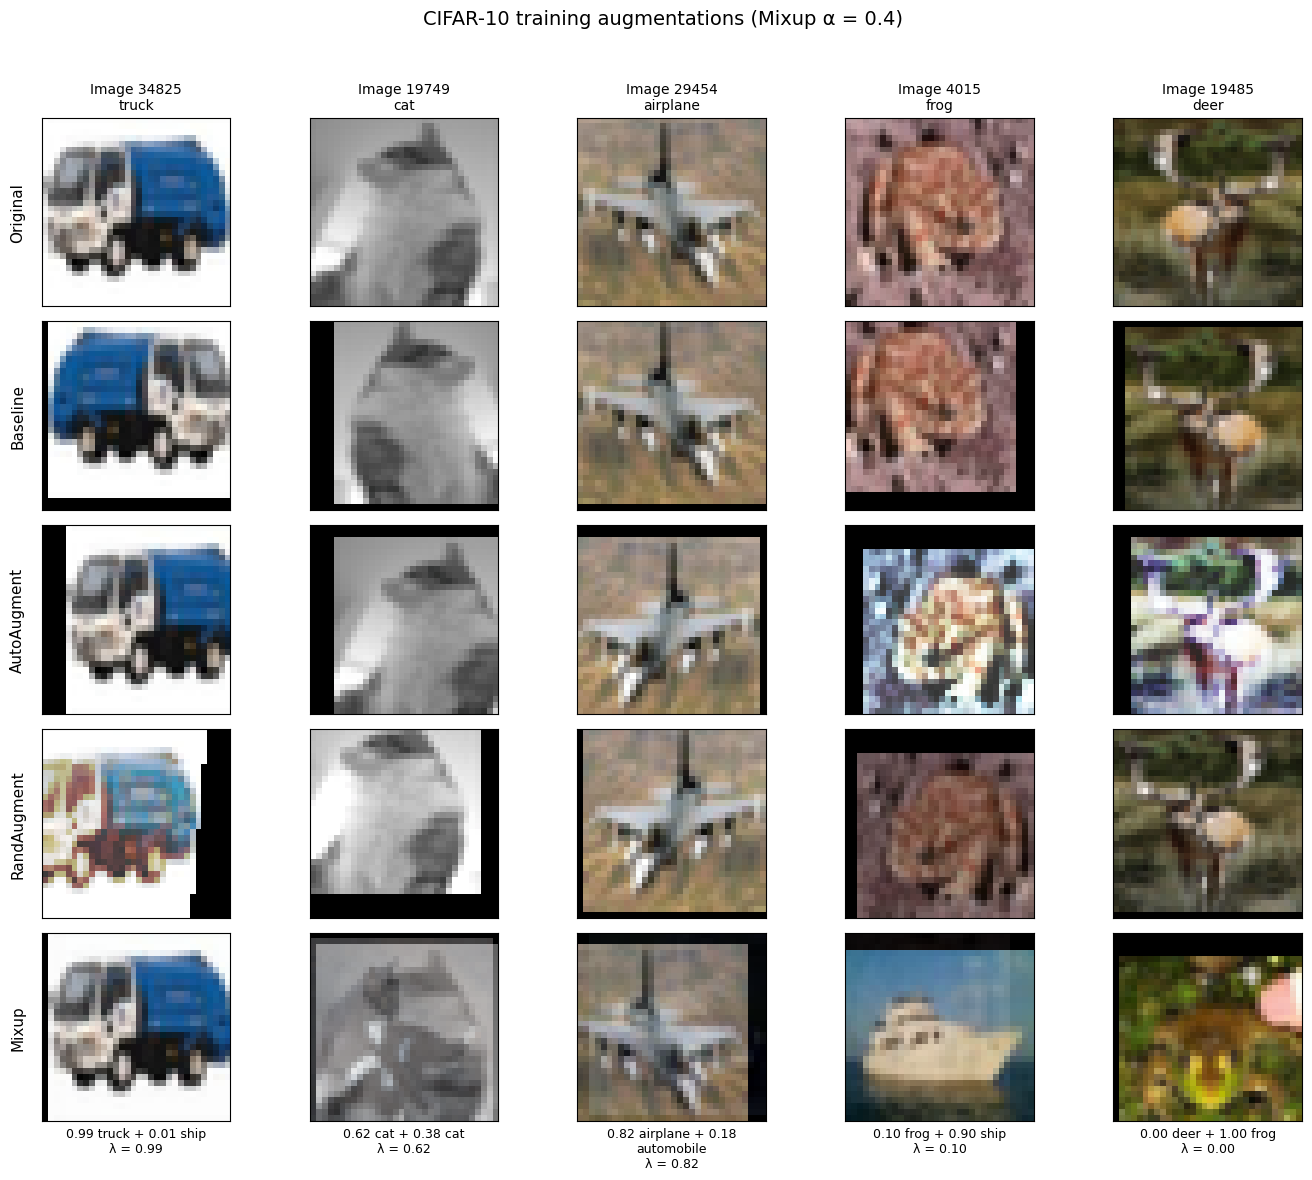

In [7]:
import textwrap

class_names = (
  "airplane", "automobile", "bird", "cat", "deer",
  "dog", "frog", "horse", "ship", "truck",
)
methods = ("baseline", "autoaugment", "randaugment", "mixup")
row_names = ("Original", "Baseline", "AutoAugment", "RandAugment", "Mixup")

alpha = 0.4
rng = np.random.default_rng(SEED)
indices = rng.choice(len(X_train), size=5, replace=False)
# Choose a different training image for each Mixup partner.
partner_indices = (
  indices + rng.integers(1, len(X_train), size=len(indices))
) % len(X_train)
coefficients = rng.beta(alpha, alpha, size=len(indices))

mean = torch.tensor(CIFAR10_MEAN).view(3, 1, 1)
std = torch.tensor(CIFAR10_STD).view(3, 1, 1)


def display_image(tensor):
  image = tensor.detach().cpu()
  return (image * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


fig, axes = plt.subplots(5, len(indices), figsize=(14, 12))
python_state = random.getstate()
numpy_state = np.random.get_state()

try:
  # Preserve the CPU RNG used by torchvision's stochastic transforms.
  with torch.random.fork_rng(devices=[]):
    torch.manual_seed(SEED)
    random.seed(SEED)
    np.random.seed(SEED)

    for column, index in enumerate(indices):
      source_class = class_names[int(y_train[index])]
      axes[0, column].imshow(X_train[index])
      axes[0, column].set_title(
        f"Image {int(index)}\n{source_class}", fontsize=10
      )

      for row, method in enumerate(methods, start=1):
        dataset = loaders[method]["train"].dataset
        image, label = dataset[int(index)]

        if method == "mixup":
          partner, partner_label = dataset[int(partner_indices[column])]
          coefficient = float(coefficients[column])
          image = coefficient * image + (1 - coefficient) * partner
          partner_class = class_names[partner_label]

          # The corresponding soft target has these same class weights.
          caption = (
            f"{coefficient:.2f} {class_names[label]} + "
            f"{1 - coefficient:.2f} {partner_class}\n"
            f"λ = {coefficient:.2f}"
          )
          axes[row, column].set_xlabel(
            "\n".join(
              textwrap.fill(line, width=28)
              for line in caption.splitlines()
            ),
            fontsize=9,
          )

        axes[row, column].imshow(display_image(image))

finally:
  random.setstate(python_state)
  np.random.set_state(numpy_state)

for row, row_name in enumerate(row_names):
  axes[row, 0].set_ylabel(row_name, fontsize=11, labelpad=12)
  for axis in axes[row]:
    axis.set_xticks([])
    axis.set_yticks([])

fig.suptitle(
  f"CIFAR-10 training augmentations (Mixup α = {alpha})",
  fontsize=14,
)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

From the visualization, we can observe that each augmentation method introduces different types of variation into the CIFAR-10 images. The baseline transformations generally preserve the original appearance of the objects, while AutoAugment and RandAugment can introduce more noticeable changes in color, contrast, and positioning.

Mixup behaves differently by combining two training examples according to a randomly sampled interpolation coefficient. As shown in the figure, the resulting image can closely resemble one of the original examples or contain visible features from both, depending on the value of $\lambda$.

Although these examples help illustrate the differences between the augmentation strategies, they do not establish which method improves classification performance. We will investigate that question through controlled CNN training experiments.

Speaking of which, let's move onto the actual CNN architecture.

## CNN Architecture
Now that we've established our augmentation pipelines, the next step is to construct the CNN that we'll use to evaluate each method. Since the main objective of this experiment is to compare augmentation strategies rather than neural network architectures, I'll use the same CNN architecture across all four configurations to keep the comparison consistent.

The network consists of three convolutional stages with increasing channel sizes of 32, 64, and 128. Each stage contains two convolutional layers with $3\times3$ kernels, followed by batch normalization, ReLU activation functions, and max pooling. As the images pass through the network, their spatial dimensions decrease while the number of feature channels increases, allowing the CNN to learn progressively more complex image representations.

After the final convolutional stage, global average pooling reduces each feature map to a single value, producing a 128-dimensional feature vector. A fully connected layer then maps this representation to 10 output logits, corresponding to the CIFAR-10 classes.

To ensure a controlled comparison, each experimental run will use identical initial model weights, optimizer settings, and training budgets. This allows us to focus on how the different augmentation methods influence learning and generalization, rather than differences caused by the network architecture itself.

In [8]:
class CIFAR10CNN(nn.Module):
  """Three convolutional stages followed by global average pooling."""

  def __init__(self, num_classes=10):
    super().__init__()

    def conv_stage(in_channels, out_channels):
      return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
      )

    self.features = nn.Sequential(
      conv_stage(3, 32),     # 32 × 16 × 16
      conv_stage(32, 64),    # 64 × 8 × 8
      conv_stage(64, 128),   # 128 × 4 × 4
    )
    self.pool = nn.AdaptiveAvgPool2d(1)
    self.classifier = nn.Linear(128, num_classes)

  def forward(self, images):
    features = self.features(images)
    features = self.pool(features).flatten(1)
    return self.classifier(features)  # Raw logits for cross-entropy.

In [9]:
def create_model(seed=SEED, target_device=device):
  """Return a fresh model with identical initialization for the same seed."""
  # Initialize on CPU while preserving the caller's random state.
  with torch.random.fork_rng(devices=[]):
    torch.manual_seed(seed)
    model = CIFAR10CNN()

  return model.to(target_device)


# Call create_model() separately for each augmentation experiment.

In [10]:
model = create_model()

# Evaluation mode prevents this shape check from updating BatchNorm statistics.
model.eval()
with torch.inference_mode():
  dummy_batch = torch.zeros(8, 3, 32, 32, device=device)
  logits = model(dummy_batch)

assert logits.shape == (8, 10), f"Unexpected output shape: {logits.shape}"
model.train()

trainable_parameters = sum(
  parameter.numel() for parameter in model.parameters()
  if parameter.requires_grad
)
print(f"Output shape: {tuple(logits.shape)}")
print(f"Trainable parameters: {trainable_parameters:,}")

Output shape: (8, 10)
Trainable parameters: 288,746


### Training and Evaluation



We compare the four augmentation configurations using the same CNN architecture, identical initial weights, optimizer, learning-rate schedule, and epoch budget. Baseline, AutoAugment, and RandAugment use ordinary cross-entropy on integer class targets. For a batch of size $B$,

$$
\mathcal{L}_{CE}
=
-\frac{1}{B}\sum_{i=1}^{B}\log p_\theta(y_i\mid x_i).
$$

AutoAugment and RandAugment are applied directly by their respective training datasets. Mixup instead operates inside the training loop on images produced by the baseline preprocessing.

For each mini-batch, a random permutation $\pi$ pairs training examples, and a single mixing coefficient $\lambda$ is sampled from a Beta distribution:

$$
\tilde{x}_i
=
\lambda x_i+(1-\lambda)x_{\pi(i)},
\qquad
\lambda\sim\operatorname{Beta}(\alpha,\alpha).
$$

Since Mixup interpolates between both the input images and their corresponding labels, its training objective can be written as

$$
\mathcal{L}_{Mixup}
=
\frac{1}{B}\sum_{i=1}^{B}
\left[
\lambda\,\ell(f_\theta(\tilde{x}_i),y_i)
+
(1-\lambda)\,\ell(f_\theta(\tilde{x}_i),y_{\pi(i)})
\right],
$$

where $\ell$ represents the cross-entropy loss for an individual training example.

This weighted formulation is mathematically equivalent to calculating cross-entropy against the interpolated soft labels. Because cross-entropy is linear in the target distribution, the loss can be evaluated without explicitly constructing one-hot label vectors.

Validation uses the same deterministic preprocessing, ordinary cross-entropy, and classification accuracy for every method. Losses are averaged by sample count, including the final partial batch.

We record each method's training objective, but Mixup uses a different target distribution from the other methods. Therefore, its training loss is not directly comparable to the ordinary cross-entropy losses reported for the other configurations. No training accuracy is reported.

The test set remains untouched during training and hyperparameter selection.

#### Shared Hyperparameters

All four CNNs use stochastic gradient descent (SGD) with momentum and the same cosine learning-rate schedule. The hyperparameters are fixed across experiments to maintain a controlled comparison, rather than individually tuned for each augmentation method.

Full-precision training is used throughout to maintain a consistent implementation.

#### Learning-Rate Scheduling

Rather than maintaining a constant learning rate throughout training, cosine annealing gradually reduces the step size according to

$$
\eta_t
=
\eta_{\min}
+
\frac{1}{2}(\eta_{\max}-\eta_{\min})
\left(
1+\cos\left(\frac{\pi t}{T}\right)
\right),
$$

where $\eta_t$ is the learning rate at scheduler step $t$, $\eta_{\max}$ is the initial learning rate, $\eta_{\min}$ is the minimum learning rate, and $T$ is the scheduling horizon.

In this experiment, the initial learning rate is $0.1$, with a cosine schedule configured over 50 epochs.

Since the scheduler is stepped after each epoch, the final training epoch uses the learning rate corresponding to $t=49$, rather than $t=50$. With $\eta_{\min}=0$ and $T=50$, this gives

$$
\eta_{49}
=
\frac{0.1}{2}
\left(
1+\cos\left(\frac{49\pi}{50}\right)
\right)
\approx 9.87\times10^{-5}.
$$

Thus, the learning rate decays to approximately zero by the end of training, rather than reaching exactly zero during the final epoch.

The motivation behind cosine annealing is to permit relatively large parameter updates during early training while progressively reducing the step size as optimization proceeds.

Using the same schedule across all four experiments ensures that differences in learning-rate behavior do not become an additional experimental variable.



In [11]:
TRAIN_CONFIG = {
  "optimizer": "sgd",
  "learning_rate": 0.1,
  "momentum": 0.9,
  "weight_decay": 5e-4,
  "scheduler": "cosine",
  "min_learning_rate": 0.0,
  "epochs": 50,
  "mixup_alpha": 0.4,
}
EXPERIMENT_NAMES = ("baseline", "autoaugment", "randaugment", "mixup")


#### Mixup Implementation

Unlike AutoAugment and RandAugment, which transform individual images during data loading, Mixup operates directly on batches during training.

For each batch, I randomly permute the sample indices to construct image pairs and draw an interpolation coefficient $\lambda$ from the Beta distribution. The resulting images are linear combinations of the paired examples.

Since normalization is an affine transformation, applying Mixup to normalized images is mathematically equivalent to mixing the original images first and then normalizing them, provided both images use the same normalization parameters.

Rather than explicitly constructing soft-label vectors, I calculate a weighted combination of two cross-entropy losses. This implements the Mixup objective while retaining the original integer class labels.


In [12]:
def mixup_batch(images, targets, alpha, rng, pair_generator):
  if alpha <= 0:
    raise ValueError("Mixup alpha must be positive.")
  
  coefficient = float(rng.beta(alpha, alpha))
  permutation = torch.randperm(
    images.size(0), generator=pair_generator
  ).to(images.device)
  
  mixed_images = coefficient * images + (1 - coefficient) * images[permutation]
  return mixed_images, targets, targets[permutation], coefficient


#### Training and Validation Functions

The training procedure updates the CNN parameters using stochastic gradient descent with momentum. For each mini-batch, the model computes predictions, evaluates the appropriate loss function, calculates gradients through backpropagation, and updates its parameters.

For the baseline, AutoAugment, and RandAugment experiments, training uses standard cross-entropy loss. Mixup instead uses the weighted cross-entropy objective derived earlier.

After each training epoch, I evaluate the model on the validation set without updating its parameters. Validation is performed using the same preprocessing and loss function across all four configurations, making validation accuracy directly comparable.

The training and validation losses are averaged according to the number of samples rather than the number of batches. This accounts for the possibility that the final mini-batch contains fewer observations.

I also record training time to compare the computational cost of each augmentation method. CUDA synchronization is used when measuring GPU execution time to avoid underestimating the duration of asynchronous operations.


In [13]:
# Define GPU synchronization, single-epoch training, and validation functions.

def synchronize_device(target_device):
  if target_device.type == "cuda":
    torch.cuda.synchronize(target_device)


def train_one_epoch(
  model,
  loader,
  optimizer,
  criterion,
  configuration,
  target_device,
  mixup_alpha=0.4,
  mixup_rng=None,
  pair_generator=None
):
  # Validate experiment configuration.
  if configuration not in EXPERIMENT_NAMES:
    raise ValueError(f"Unknown configuration: {configuration}")

  if configuration == "mixup" and (mixup_rng is None or pair_generator is None):
    raise ValueError("Mixup requires its local random generators.")

  # Initialize training mode and metric accumulators.
  model.train()

  loss_sum = torch.zeros((), device=target_device)
  sample_count = 0

  synchronize_device(target_device)
  start = time.perf_counter()

  # Train the model over one complete epoch.
  for images, targets in loader:
    images = images.to(target_device, non_blocking=True)
    targets = targets.to(target_device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)

    # Apply Mixup only for the designated experiment.
    if configuration == "mixup":
      images, targets_a, targets_b, coefficient = mixup_batch(
        images,
        targets,
        mixup_alpha,
        mixup_rng,
        pair_generator
      )

      logits = model(images)

      loss = (
        coefficient * criterion(logits, targets_a)
        + (1 - coefficient) * criterion(logits, targets_b)
      )

    else:
      logits = model(images)
      loss = criterion(logits, targets)

    # Update model parameters using backpropagation.
    loss.backward()
    optimizer.step()

    # Accumulate sample-weighted training loss.
    loss_sum += loss.detach() * targets.size(0)
    sample_count += targets.size(0)

  # Calculate average training loss and elapsed time.
  synchronize_device(target_device)
  elapsed = time.perf_counter() - start

  average_loss = loss_sum.item() / sample_count

  return average_loss, elapsed


@torch.inference_mode()
def evaluate_validation(model, loader, criterion, target_device):
  # Initialize evaluation mode and metric accumulators.
  model.eval()

  loss_sum = torch.zeros((), device=target_device)
  correct = torch.zeros((), dtype=torch.long, device=target_device)
  sample_count = 0

  # Evaluate the model without computing gradients.
  for images, targets in loader:
    images = images.to(target_device, non_blocking=True)
    targets = targets.to(target_device, non_blocking=True)

    logits = model(images)

    loss_sum += criterion(logits, targets) * targets.size(0)
    correct += (logits.argmax(dim=1) == targets).sum()
    sample_count += targets.size(0)

  # Calculate sample-weighted validation loss and accuracy.
  average_loss = loss_sum.item() / sample_count
  accuracy = correct.item() / sample_count

  return average_loss, accuracy



#### Experiment Runner

To isolate the effects of data augmentation, I train four independent CNNs using the same architecture, initial model parameters, optimizer, learning-rate schedule, and number of epochs.

Before each experiment, the random seeds and data-loader generators are reset to improve consistency between runs. Consequently, differences in validation performance can be investigated primarily in relation to the augmentation strategy, although stochastic training and GPU nondeterminism remain potential sources of variation.

Each experiment records training loss, validation loss, validation accuracy, learning rate, and execution time after every epoch. The trained models and their corresponding histories are retained for subsequent test-set evaluation and graphical comparisons.

The four configurations are trained sequentially to reduce GPU memory requirements.


In [14]:
# Run individual and sequential augmentation experiments.

def run_experiment(configuration, config=None, epochs=None):
  # Validate experiment configuration.
  if configuration not in EXPERIMENT_NAMES:
    raise ValueError(f"Unknown configuration: {configuration}")

  settings = dict(TRAIN_CONFIG)
  if config is not None:
    settings.update(config)

  epoch_budget = settings["epochs"] if epochs is None else epochs

  if not isinstance(epoch_budget, int) or not 1 <= epoch_budget <= settings["epochs"]:
    raise ValueError("Epoch budget must be an integer within the schedule horizon.")

  if settings["optimizer"] != "sgd" or settings["scheduler"] != "cosine":
    raise ValueError("This setup supports SGD with a cosine scheduler.")

  if settings["mixup_alpha"] <= 0:
    raise ValueError("Mixup alpha must be positive.")

  # Reset random seeds for reproducibility.
  random.seed(SEED)
  np.random.seed(SEED)
  torch.manual_seed(SEED)

  if device.type == "cuda":
    torch.cuda.manual_seed_all(SEED)

  experiment_loaders = loaders[configuration]

  for split, offset in (("train", 0), ("val", 1)):
    experiment_loaders[split].generator.manual_seed(SEED + offset)

  # Initialize the model, loss function, optimizer, and scheduler.
  model = create_model(seed=SEED, target_device=device)
  criterion = nn.CrossEntropyLoss()

  optimizer = torch.optim.SGD(
    model.parameters(),
    lr=settings["learning_rate"],
    momentum=settings["momentum"],
    weight_decay=settings["weight_decay"]
  )

  scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=settings["epochs"],
    eta_min=settings["min_learning_rate"]
  )

  # Initialize random generators for Mixup.
  mixup_rng = np.random.default_rng(SEED)
  pair_generator = torch.Generator().manual_seed(SEED)

  # Initialize experiment history.
  history = {
    "configuration": configuration,
    "seed": SEED,
    "settings": settings,
    "epochs_run": epoch_budget,
    "epochs": []
  }

  # Train and validate the model.
  synchronize_device(device)
  start = time.perf_counter()

  for epoch in range(1, epoch_budget + 1):
    learning_rate = optimizer.param_groups[0]["lr"]

    train_loss, train_seconds = train_one_epoch(
      model,
      experiment_loaders["train"],
      optimizer,
      criterion,
      configuration,
      device,
      settings["mixup_alpha"],
      mixup_rng,
      pair_generator
    )

    val_loss, val_accuracy = evaluate_validation(
      model,
      experiment_loaders["val"],
      criterion,
      device
    )

    scheduler.step()
    synchronize_device(device)

    # Record epoch metrics.
    history["epochs"].append({
      "epoch": epoch,
      "learning_rate": learning_rate,
      "train_loss": train_loss,
      "val_loss": val_loss,
      "val_accuracy": val_accuracy,
      "train_seconds": train_seconds,
      "elapsed_seconds": time.perf_counter() - start
    })

    # Display progress at the first, every tenth, and final epoch.
    if epoch == 1 or epoch % 10 == 0 or epoch == epoch_budget:
      print(
        f"{configuration} | Epoch {epoch:02d}/{epoch_budget} | "
        f"Val Acc: {val_accuracy:.2%} | "
        f"Train Time: {train_seconds:.2f}s",
        flush=True
      )

  # Summarize total experiment runtime.
  synchronize_device(device)

  history["total_seconds"] = time.perf_counter() - start
  history["total_train_seconds"] = sum(
    record["train_seconds"]
    for record in history["epochs"]
  )

  return model, history


def run_experiments(configurations=EXPERIMENT_NAMES, config=None, epochs=None):
  # Execute each configuration independently.
  results = {}

  for configuration in configurations:
    model, history = run_experiment(
      configuration,
      config=config,
      epochs=epochs
    )

    results[configuration] = {
      "model": model.cpu(),
      "history": history
    }

  return results



#### Computational Benchmark

Before conducting the full training experiments, I perform a one-epoch benchmark for each augmentation configuration to estimate its computational cost.

Each benchmark uses the same CNN architecture and training settings, allowing me to compare the approximate time required to process one training epoch. This is particularly relevant because AutoAugment and RandAugment perform additional image transformations during data loading, potentially increasing their computational overhead.

The benchmark also provides an estimate of the resources needed for the full experiment. Based on these measurements, I use a common 50-epoch training budget for all four configurations.

The benchmark is intended to evaluate computational feasibility rather than final predictive performance. Consequently, the one-epoch accuracy measurements are not used to determine which augmentation strategy performs best.


In [15]:
import gc

def benchmark_one_epoch(config=None):
  """Benchmark all four methods without retaining trained models."""
  settings = dict(TRAIN_CONFIG)
  if config is not None:
    settings.update(config)
  records = []
  names = {
    "baseline": "Baseline", "autoaugment": "AutoAugment",
    "randaugment": "RandAugment", "mixup": "Mixup",
  }
  for configuration in EXPERIMENT_NAMES:
    gc.collect()
    synchronize_device(device)
    if device.type == "cuda":
      with torch.cuda.device(device):
        torch.cuda.empty_cache()
      torch.cuda.reset_peak_memory_stats(device)

    benchmark_model = None
    try:
      synchronize_device(device)
      start = time.perf_counter()
      benchmark_model, history = run_experiment(
        configuration, config=settings, epochs=1
      )
      synchronize_device(device)
      total_seconds = time.perf_counter() - start
      peak_memory = (
        torch.cuda.max_memory_allocated(device) / (1024 ** 2)
        if device.type == "cuda" else float("nan")
      )
      epoch = history["epochs"][0]
      records.append({
        "configuration": names[configuration],
        "train_seconds": epoch["train_seconds"],
        "total_seconds": total_seconds,
        "val_loss": epoch["val_loss"],
        "val_accuracy_pct": 100 * epoch["val_accuracy"],
        "peak_gpu_mib": peak_memory,
        "projected_full_run_minutes": (
          history["total_seconds"] * settings["epochs"] / 60
        ),
      })
    finally:
      del benchmark_model
      gc.collect()
      if device.type == "cuda":
        synchronize_device(device)
        with torch.cuda.device(device):
          torch.cuda.empty_cache()

  return pd.DataFrame.from_records(records).set_index("configuration")


In [16]:
benchmark_results = benchmark_one_epoch()
benchmark_results.round(3)


baseline | Epoch 01/1 | Val Acc: 49.06% | Train Time: 10.78s
autoaugment | Epoch 01/1 | Val Acc: 50.38% | Train Time: 18.43s
randaugment | Epoch 01/1 | Val Acc: 52.34% | Train Time: 18.41s
mixup | Epoch 01/1 | Val Acc: 53.96% | Train Time: 10.25s


,train_seconds,total_seconds,val_loss,val_accuracy_pct,peak_gpu_mib,projected_full_run_minutes
configuration,,,,,,
Baseline,10.782,11.271,1.511,49.06,367.284,9.383
AutoAugment,18.425,18.892,1.363,50.38,367.284,15.736
RandAugment,18.407,18.817,1.292,52.34,367.284,15.674
Mixup,10.248,10.674,1.312,53.96,367.285,8.887


#### Computational Benchmark Results

The one-epoch benchmark shows that AutoAugment and RandAugment require approximately 18.4 seconds of training per epoch, compared with 10.8 seconds for the baseline and 10.2 seconds for Mixup. Because these augmentations run on the CPU inside the data-loader workers, this slowdown reflects input-pipeline throughput on this Kaggle machine with 2 workers, not a property of the methods in general. For the same reason, peak GPU memory is nearly identical across configurations (about 367 MiB), which is expected rather than a finding about the methods.

These measurements suggest that the primary computational tradeoff is training time rather than GPU memory consumption. With projected total runtimes ranging from approximately 9 to 16 minutes per configuration, I proceed with 50 epochs for each method to evaluate their generalization performance under a consistent training budget.

## Training the Models
Now that we have everything setup, as well as a test benchmark to see how all four configurations will do, let's finally move onto to actually training the models.

In [17]:
# Full training experiment
FULL_EPOCHS = 50

full_results = run_experiments(
  configurations=EXPERIMENT_NAMES,
  epochs=FULL_EPOCHS
)

print("All four training experiments completed.")

baseline | Epoch 01/50 | Val Acc: 46.40% | Train Time: 10.22s
baseline | Epoch 10/50 | Val Acc: 73.18% | Train Time: 10.01s
baseline | Epoch 20/50 | Val Acc: 78.24% | Train Time: 10.07s
baseline | Epoch 30/50 | Val Acc: 84.80% | Train Time: 10.21s
baseline | Epoch 40/50 | Val Acc: 88.16% | Train Time: 9.81s
baseline | Epoch 50/50 | Val Acc: 90.58% | Train Time: 9.80s
autoaugment | Epoch 01/50 | Val Acc: 44.44% | Train Time: 17.90s
autoaugment | Epoch 10/50 | Val Acc: 73.36% | Train Time: 17.66s
autoaugment | Epoch 20/50 | Val Acc: 71.88% | Train Time: 17.66s
autoaugment | Epoch 30/50 | Val Acc: 84.06% | Train Time: 17.71s
autoaugment | Epoch 40/50 | Val Acc: 87.34% | Train Time: 17.54s
autoaugment | Epoch 50/50 | Val Acc: 89.66% | Train Time: 17.78s
randaugment | Epoch 01/50 | Val Acc: 46.56% | Train Time: 18.28s
randaugment | Epoch 10/50 | Val Acc: 74.18% | Train Time: 18.05s
randaugment | Epoch 20/50 | Val Acc: 77.16% | Train Time: 18.22s
randaugment | Epoch 30/50 | Val Acc: 81.64% |

## Training Analysis
Now that the epochs have been trained, let's go ahead and analyze the performances of each data augmentation method. To begin, let's compare their final validation accuracy with the highest validation accuracy achieved during training. The final accuracy measures performance at the end of the training schedule, while the best accuracy identifies the model's strongest observed validation performance and the epoch at which it occurred.

This comparision allows me to examine whether validation performance continued improving throughout training or peaked earlier. The total training time is also included to assess the computational cost of each method.

In [18]:
summary_rows = []

for name, result in full_results.items():
  history = result["history"]
  records = history["epochs"]

  best_epoch = max(
    records, key=lambda record: record["val_accuracy"]
  )

  summary_rows.append({
    "Method": name,
    "Final Accuracy (%)": 100 * records[-1]["val_accuracy"],
    "Best Accuracy (%)": 100 * best_epoch["val_accuracy"],
    "Best Epoch": best_epoch["epoch"],
    "Training Time (min)": history["total_train_seconds"] / 60,
  })

summary_df = pd.DataFrame(summary_rows)
display(summary_df.round(2))

,Method,Final Accuracy (%),Best Accuracy (%),Best Epoch,Training Time (min)
0,baseline,90.58,90.58,50,8.36
1,autoaugment,89.66,90.02,46,14.80
2,randaugment,90.42,90.46,47,15.18
3,mixup,90.06,90.06,46,8.37


The baseline achieved the highest final validation accuracy at 90.58%, followed closely by RandAugment at 90.42%. The baseline peaked at the final epoch, while AutoAugment and RandAugment peaked slightly earlier (epochs 46 and 47, by 0.36 and 0.04 percentage points over their final values). Mixup’s best accuracy (epoch 46) equals its final accuracy. Because “best epoch” is selected on the validation set, it is optimistically biased, so I compare methods by final accuracy. The four final validation accuracies span under one percentage point, which is comparable to the sampling uncertainty of a 5,000-image validation set (about ±0.4 percentage points per model).

In terms of computational cost, AutoAugment and RandAugment required approximately 1.8 times the baseline’s training time, while Mixup’s was nearly identical. These timings are specific to this hardware and data-loading setup. Neither augmentation method showed a clear validation advantage over the baseline despite the added cost of AutoAugment and RandAugment.

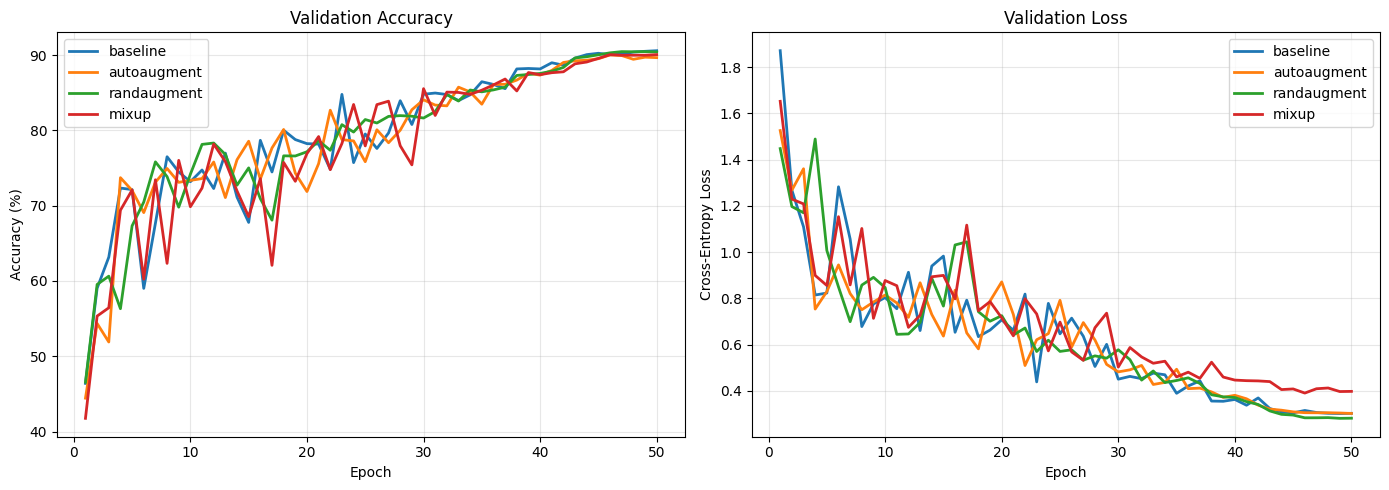

In [19]:
# Compare validation accuracy and loss throughout training for all four methods.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, result in full_results.items():
  records = result["history"]["epochs"]

  epochs = [r["epoch"] for r in records]
  val_accuracy = [100 * r["val_accuracy"] for r in records]
  val_loss = [r["val_loss"] for r in records]

  axes[0].plot(epochs, val_accuracy, label=name, linewidth=2)
  axes[1].plot(epochs, val_loss, label=name, linewidth=2)

axes[0].set_title("Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")

axes[1].set_title("Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy Loss")

for ax in axes:
  ax.legend()
  ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

As for the performance itself, as show on these two graphs, we can see that the validation accuracy curves show substantial fluctuations during early training, followed by more gradual improvements as all four models approach approximately 90% accuracy. Similarly, validation losses generally decrease throughout training, consistent with convergence under the cosine learning-rate schedule.

Although the accuracy curves become closely aligned near the final epochs, Mixup ends with a noticeably higher validation loss (roughly 0.40 versus 0.30 for the other methods). Similar accuracy does not imply similar cross-entropy, since the loss depends on the confidence assigned to each prediction. I did not test why Mixup’s loss is higher. Possible explanations include differences in prediction confidence caused by training on soft targets, or a mismatch between BatchNorm statistics learned on mixed images and those of clean validation images. Both are untested hypotheses.

In [20]:
# Evaluate each trained CNN on the held-out CIFAR-10 test set.

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

def evaluate_test_model(model, test_loader, device):
  model = model.to(device)
  model.eval()

  all_labels = []
  all_predictions = []

  with torch.inference_mode():
    for images, labels in test_loader:
      images = images.to(device)

      logits = model(images)
      predictions = logits.argmax(dim=1)

      all_labels.extend(labels.cpu().numpy())
      all_predictions.extend(predictions.cpu().numpy())

  all_labels = np.asarray(all_labels)
  all_predictions = np.asarray(all_predictions)

  return {
    "accuracy": accuracy_score(all_labels, all_predictions),
    "macro_f1": f1_score(
      all_labels, all_predictions, average="macro"
    ),
    "labels": all_labels,
    "predictions": all_predictions,
    "confusion_matrix": confusion_matrix(
      all_labels, all_predictions, labels=np.arange(10)
    ),
  }


test_results = {}

for name, result in full_results.items():
  test_results[name] = evaluate_test_model(
    result["model"],
    loaders[name]["test"],
    device
  )

  print(
    f"{name}: "
    f"Accuracy = {100 * test_results[name]['accuracy']:.2f}%, "
    f"Macro F1 = {test_results[name]['macro_f1']:.4f}"
  )

baseline: Accuracy = 90.02%, Macro F1 = 0.9002
autoaugment: Accuracy = 89.93%, Macro F1 = 0.8989
randaugment: Accuracy = 90.58%, Macro F1 = 0.9055
mixup: Accuracy = 89.58%, Macro F1 = 0.8958


#### Overall Performance Comparison

Having evaluated each model on the held-out test set, let's now consolidate the validation accuracy, test accuracy, macro F1-score, and training time into a single table. This provides a direct comparison of predictive performance and computational cost across all four augmentation strategies.

In [21]:
# Summarize validation performance, test accuracy, F1-score, and training cost.

comparison_rows = []

for name, result in full_results.items():
  records = result["history"]["epochs"]
  test = test_results[name]

  comparison_rows.append({
    "Method": name,
    "Final Val Accuracy (%)": 100 * records[-1]["val_accuracy"],
    "Test Accuracy (%)": 100 * test["accuracy"],
    "Macro F1": test["macro_f1"],
    "Training Time (min)": result["history"]["total_train_seconds"] / 60,
  })

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df.round(3))

,Method,Final Val Accuracy (%),Test Accuracy (%),Macro F1,Training Time (min)
0,baseline,90.58,90.02,0.900,8.359
1,autoaugment,89.66,89.93,0.899,14.802
2,randaugment,90.42,90.58,0.906,15.178
3,mixup,90.06,89.58,0.896,8.375


RandAugment achieved the highest test accuracy at 90.58% and macro F1-score at 0.9055, a 0.56 percentage-point difference from the baseline’s 90.02%. AutoAugment and Mixup reached 89.93% and 89.58%. This difference should be interpreted cautiously. For two models evaluated on 10,000 test images, the unpaired 95% interval for an accuracy difference is roughly ±0.8 percentage points, and this is a single training run per method. In addition, the baseline ranked first on final validation accuracy while RandAugment ranked first on test accuracy. This reversal is itself consistent with differences of this size being within noise. This experiment therefore does not establish that any method outperforms the baseline.

Interestingly, RandAugment performed best on the held-out test set despite the baseline achieving the highest validation accuracy. However, the relatively small differences between methods suggest that no augmentation strategy provided a substantial generalization advantage in this experiment.

To examine the classification results in greater detail, I use confusion matrices to visualize how each model distributes its predictions across the ten CIFAR-10 classes. Each row represents the true class, while each column represents the predicted class. Correct predictions appear along the main diagonal, whereas off-diagonal entries represent misclassifications.

Unlike overall test accuracy and macro F1-score, which summarize performance numerically, confusion matrices reveal which classes are most frequently confused. This provides a more detailed comparison of how the four augmentation strategies affect classification behavior.

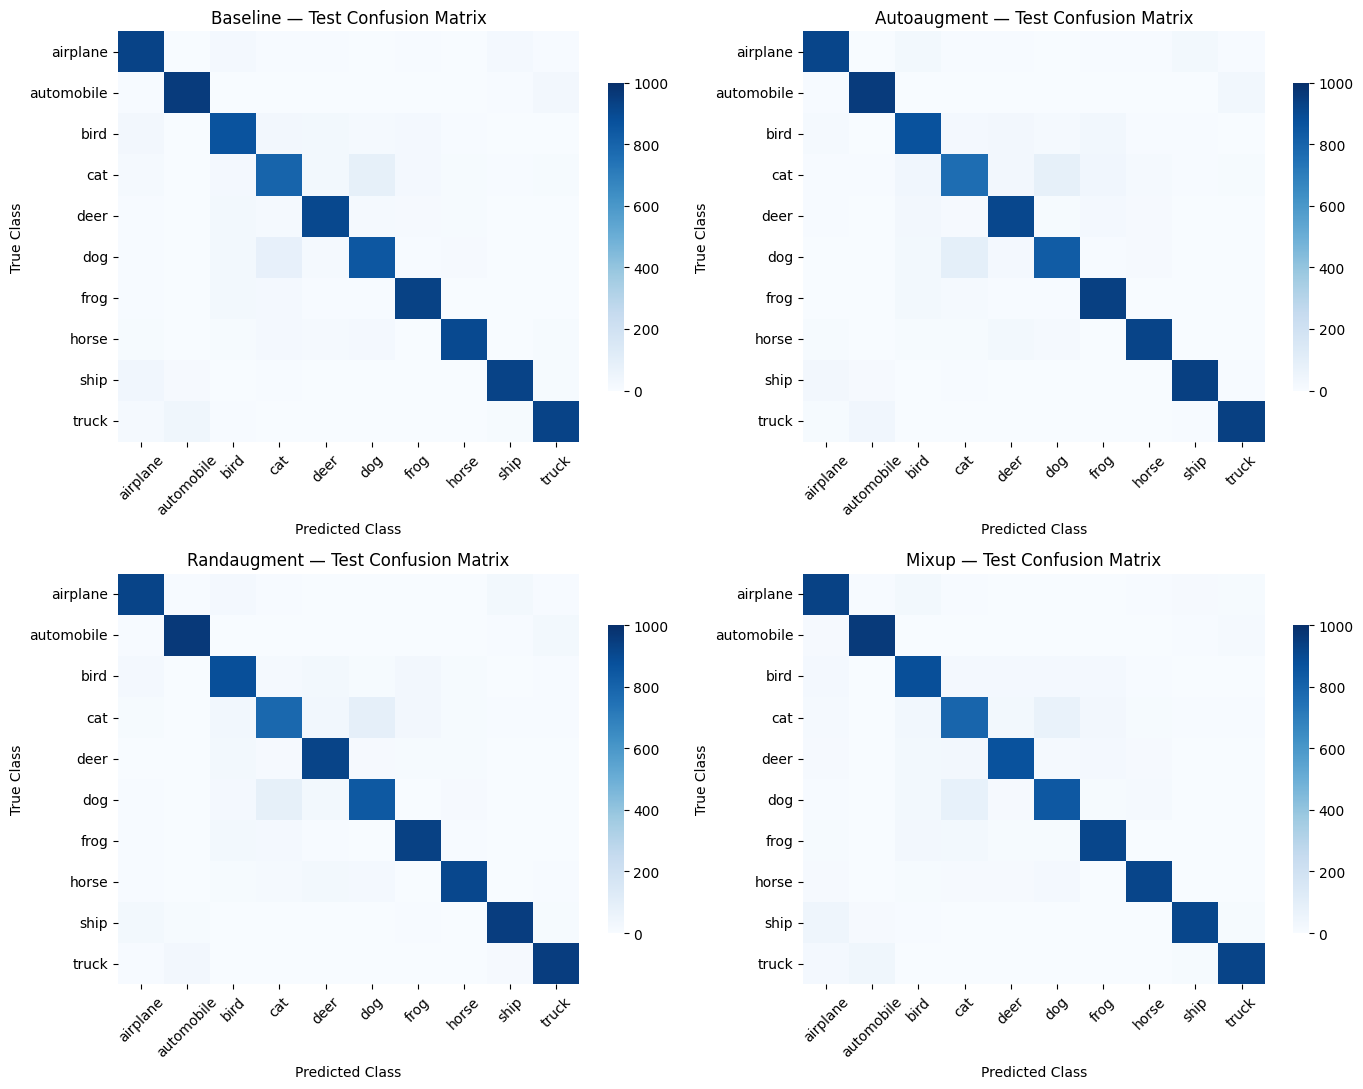

In [25]:
# Compare test-set confusion matrices across the four augmentation methods.

import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, (name, result) in zip(axes.flat, test_results.items()):
  cm = result["confusion_matrix"]

  sns.heatmap(
    cm,
    annot=False,
    cmap="Blues",
    vmin=0,
    vmax=1000,
    xticklabels=class_names,
    yticklabels=class_names,
    ax=ax,
    cbar=True,
    cbar_kws={"shrink": 0.75}
  )

  ax.set_title(f"{name.title()} — Test Confusion Matrix")
  ax.set_xlabel("Predicted Class")
  ax.set_ylabel("True Class")
  ax.tick_params(axis="x", labelrotation=45)
  ax.tick_params(axis="y", labelrotation=0)

plt.tight_layout()
plt.show()


All four confusion matrices exhibit strong diagonal patterns, indicating that most test images were classified correctly. In the heatmaps, the most visible off-diagonal errors occur between visually similar categories, particularly cats and dogs. Overall, the confusion patterns remain relatively consistent across augmentation methods, with no obvious differences suggesting that one method systematically reduces classification errors for particular classes.


These similarities suggest that the augmentation strategies did not substantially change which classes the CNN found difficult to distinguish, despite modest differences in overall test accuracy.

### Class-Wise Accuracy Analysis

While overall test accuracy summarizes each model's performance across CIFAR-10, it does not reveal how accurately individual classes are classified. To investigate this, I calculate the test accuracy for each of the ten classes under all four augmentation strategies, allowing for a more detailed comparison of their strengths and weaknesses.

Method,autoaugment,baseline,mixup,randaugment
Class,,,,
airplane,91.8,92.9,93.2,92.5
automobile,95.7,95.4,96.0,96.4
bird,87.1,86.6,88.2,88.1
cat,76.4,79.9,79.5,78.2
deer,91.2,90.9,87.1,92.2
dog,83.0,85.1,84.5,84.1
frog,93.8,93.3,91.5,93.6
horse,92.3,90.6,91.8,91.3
ship,93.9,92.8,91.7,94.6


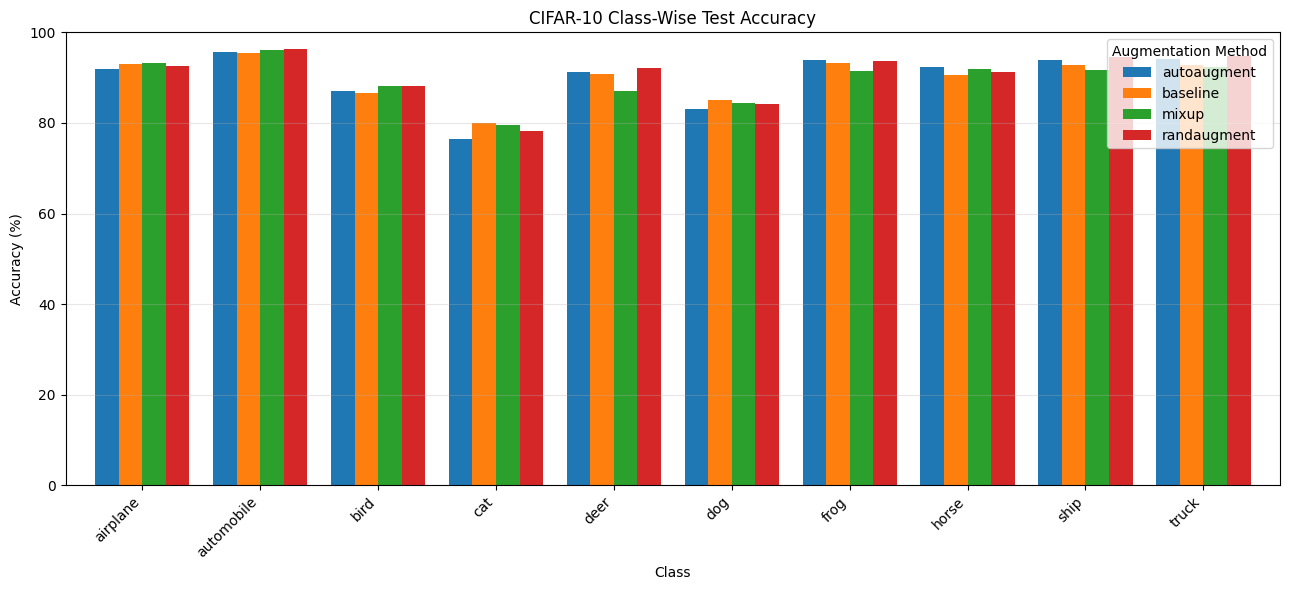

In [28]:
# Compare per-class test accuracy across the four augmentation methods.

class_accuracy_rows = []

for name, result in test_results.items():
  labels = result["labels"]
  predictions = result["predictions"]

  for class_id, class_name in enumerate(class_names):
    mask = labels == class_id

    class_accuracy_rows.append({
      "Method": name,
      "Class": class_name,
      "Accuracy (%)": 100 * np.mean(
        predictions[mask] == labels[mask]
      ),
    })

class_accuracy_df = pd.DataFrame(class_accuracy_rows)

class_accuracy_pivot = class_accuracy_df.pivot(
  index="Class",
  columns="Method",
  values="Accuracy (%)"
)

display(class_accuracy_pivot.round(2))

ax = class_accuracy_pivot.plot(
  kind="bar",
  figsize=(13, 6),
  width=0.8
)

ax.set_title("CIFAR-10 Class-Wise Test Accuracy")
ax.set_xlabel("Class")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.legend(title="Augmentation Method")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The class-wise accuracy table and grouped bar chart reveal noticeable differences in classification performance across CIFAR-10 categories. Automobiles consistently achieve over 95% accuracy, while cats remain the most difficult class, with accuracies ranging from 76.4% to 79.9%.

RandAugment attains the highest accuracy for automobiles, deer, ships, and trucks, and the baseline for cats and dogs, while Mixup and AutoAugment lead on the remaining classes. With 1,000 test images per class, the sampling uncertainty for a single class accuracy is about ±1 percentage point (one standard error), so most differences here are within noise. The largest gaps are cats (AutoAugment 76.4% versus baseline 79.9%) and deer (Mixup 87.1% versus baseline 90.9%), and even these come from one training run per method. Overall, the methods show similar class-wise patterns, and I do not find evidence of a consistent class-dependent benefit.

Although class-wise accuracy identifies which categories are more difficult to classify, it does not show the individual images responsible for these errors. To investigate these failures more closely, I examine a sample of misclassified test images from the baseline model, comparing their true labels against the model's predictions.

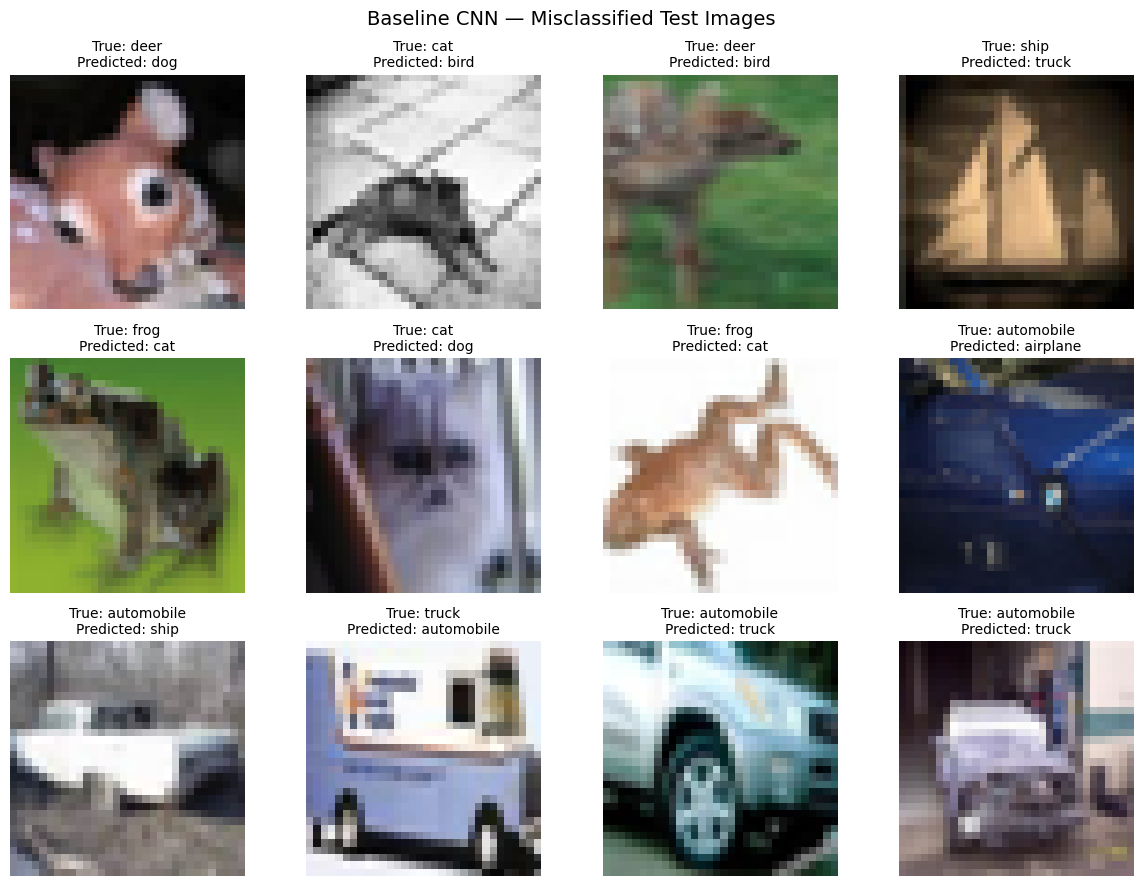

In [24]:
# Display representative CIFAR-10 test images misclassified by the baseline CNN.

baseline_test = test_results["baseline"]

incorrect_indices = np.flatnonzero(
  baseline_test["predictions"] != baseline_test["labels"]
)

rng = np.random.default_rng(SEED)
selected_indices = rng.choice(
  incorrect_indices,
  size=min(12, len(incorrect_indices)),
  replace=False
)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for ax in axes.flat:
  ax.axis("off")

for ax, index in zip(axes.flat, selected_indices):
  image = X_test[index]
  true_label = baseline_test["labels"][index]
  predicted_label = baseline_test["predictions"][index]

  ax.imshow(image)
  ax.set_title(
    f"True: {class_names[true_label]}\n"
    f"Predicted: {class_names[predicted_label]}",
    fontsize=10
  )
  ax.axis("off")

plt.suptitle("Baseline CNN — Misclassified Test Images", fontsize=14)
plt.tight_layout()
plt.show()

### Misclassification Analysis

The misclassified examples illustrate some of the challenges the baseline CNN encounters when distinguishing CIFAR-10 images. Given the dataset's low image resolution, visual similarities between categories can make certain predictions difficult, particularly when distinguishing animals with overlapping features.

These examples provide a qualitative perspective on the classification errors observed in the confusion matrices. However, because the gallery contains only a small sample of baseline errors, it cannot establish whether the other augmentation methods would make the same mistakes.

### Conclusions, Final Thoughts, and Limitations

In this experiment, I compared AutoAugment, RandAugment, and Mixup against a baseline CNN on CIFAR-10 to investigate how each affects classification accuracy and computational cost.

RandAugment had the highest test accuracy (90.58%) and macro F1-score (0.9055), 0.56 percentage points above the baseline. However, this difference is comparable to the sampling uncertainty of the test set and comes from a single seed, so the experiment does not show that RandAugment, or any other method, improves on the baseline. AutoAugment and Mixup did not exceed the baseline’s test accuracy. AutoAugment and RandAugment took roughly 1.8 times as long to train on this hardware, mainly because of CPU-side image transformation in the data loader.

Several limitations apply. First, each method was run with a single seed, so seed-to-seed variability is unmeasured. Second, I did not record training accuracy, so I cannot say whether any method reduced overfitting or changed the train–test gap. Third, I did not run a paired significance test on individual test predictions. Fourth, the experiment uses one small CNN (about 289k parameters) trained for 50 epochs. The original studies used larger networks and longer schedules, and a small model may benefit less from stronger augmentation, but I did not test this. Finally, the augmentation hyperparameters (RandAugment’s number of operations and magnitude, and Mixup’s alpha) were fixed rather than tuned.

Future work should repeat the experiments over multiple seeds, record training metrics, and vary model size, training length, and augmentation strength to determine whether any differences are consistent.

Overall, the results suggest that RandAugment offers a modest improvement in test performance at a considerable computational cost. While augmentation remains a useful technique for improving generalization, its effectiveness depends on the method, model architecture, and experimental settings. Further experiments with multiple random seeds and different augmentation strengths would help determine whether these improvements are consistent.


### References
This notebook was developed using methods described in the following research papers.

Cubuk, Ekin D., et al. "AutoAugment: Learning Augmentation Strategies from Data." *Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR)*, 2019, pp. 113–123. https://arxiv.org/abs/1805.09501.

Cubuk, Ekin Dogus, et al. "RandAugment: Practical Automated Data Augmentation with a Reduced Search Space." *Advances in Neural Information Processing Systems*, vol. 33, 2020, pp. 18613–18624. https://arxiv.org/abs/1909.13719.

Zhang, Hongyi, et al. "mixup: Beyond Empirical Risk Minimization." *International Conference on Learning Representations (ICLR)*, 2018. https://arxiv.org/abs/1710.09412.


